In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline

In [22]:
df_bc=pd.read_csv("data.csv")

In [23]:
df_bc

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [24]:
print(df_bc.shape)
print(df_bc.head())
print('data types: ',df_bc.dtypes.value_counts())
print(df_bc['diagnosis'].value_counts())

(569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  

In [25]:
print('missing values: ',df_bc.isnull().sum())
print('duplicates: ',df_bc.duplicated().sum())




missing values:  id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_wors

In [26]:

x = df_bc.drop(columns=['id', 'diagnosis', 'Unnamed: 32'])
y = (df_bc['diagnosis'] == 'M').astype(int)   # M = 1 (malignant), B = 0 (benign)

print(x.shape)          
print(y.value_counts())

(569, 30)
diagnosis
0    357
1    212
Name: count, dtype: int64


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, stratify=y, random_state=42)

In [28]:
scaler = StandardScaler().fit(X_train)
feature_names = list(x.columns)

X_train = scaler.transform(X_train)   # numpy arrays from now on: columns are picked by index

X_test  = scaler.transform(X_test)
y_train, y_test = y_train.to_numpy(),y_test.to_numpy()

n_features = X_train.shape[1]         # 30
print(X_train.shape, X_test.shape)   # (455, 30) (114, 30)
print(n_features, X_train.mean().round(3), X_train.std().round(3))


(455, 30) (114, 30)
30 0.0 1.0


In [29]:

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

def make_fitness(X_train, y_train, lam=0.1, k_neighbors=5):
    n = X_train.shape[1]

    def error_rate(s):
        cols = np.where(s == 1)[0]
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        return 1 - cross_val_score(model, X_train[:, cols], y_train, cv=5).mean()

    def fitness(s):
        if s.sum() == 0:
            return np.inf
        return error_rate(s) + lam * s.sum() / n

    return fitness, error_rate

fitness, error_rate = make_fitness(X_train, y_train, lam=0.1, k_neighbors=5)

In [30]:
# ---- 7. Swap neighborhood: 
def neighbors(s):
    for i in range(len(s)):
        s_new = s.copy()
        s_new[i] = 1 - s_new[i]
        yield s_new, i

In [31]:
# ---- 9. Tabu search (flip version) ----
def tabu_search(fitness, s_init, tenure=5, max_iter=30):
    n = len(s_init)
    s = s_init.copy()
    f_s = fitness(s)
    best_s, best_f = s.copy(), f_s

    tabu_until = np.zeros(n, dtype=int)
    history, best_history = [f_s], [best_f]
    feature_count_history, move_history = [int(s.sum())], []

    for it in range(1, max_iter + 1):
        chosen, chosen_f, chosen_move = None, np.inf, None

        for s_new, i in neighbors(s):                 # CHANGE 1: one index only
            f_new = fitness(s_new)
            is_tabu = tabu_until[i] >= it             # CHANGE 2: only i
            aspiration = f_new < best_f
            if is_tabu and not aspiration:
                continue
            if f_new < chosen_f:
                chosen, chosen_f, chosen_move = s_new, f_new, i

        if chosen is None:
            break

        s, f_s = chosen, chosen_f
        i = chosen_move
        tabu_until[i] = it + tenure                   # freeze only feature i

        if f_s < best_f:
            best_s, best_f = s.copy(), f_s

        history.append(f_s)
        best_history.append(best_f)
        feature_count_history.append(int(s.sum()))
        action = "add" if s[i] == 1 else "remove"
        move_history.append((i, action))     # CHANGE 3: new print line
        print(f"it {it:2d} | {action:<6s} {feature_names[i]:<24s} | f={f_s:.4f} | best={best_f:.4f} | k={s.sum()}")

    return best_s, best_f, history, best_history, feature_count_history, move_history


it  1 | remove symmetry_se              | f=0.0852 | best=0.0852 | k=17
it  2 | remove compactness_mean         | f=0.0797 | best=0.0797 | k=16
it  3 | remove texture_se               | f=0.0764 | best=0.0764 | k=15
it  4 | remove concave points_worst     | f=0.0708 | best=0.0708 | k=14
it  5 | remove perimeter_se             | f=0.0675 | best=0.0675 | k=13
it  6 | remove smoothness_se            | f=0.0620 | best=0.0620 | k=12
it  7 | remove compactness_worst        | f=0.0586 | best=0.0586 | k=11
it  8 | remove concavity_se             | f=0.0553 | best=0.0553 | k=10
it  9 | remove area_worst               | f=0.0520 | best=0.0520 | k=9
it 10 | remove radius_se                | f=0.0508 | best=0.0508 | k=8
it 11 | remove radius_worst             | f=0.0475 | best=0.0475 | k=7
it 12 | remove compactness_se           | f=0.0486 | best=0.0475 | k=6
it 13 | remove area_se                  | f=0.0452 | best=0.0452 | k=5
it 14 | remove concave points_mean      | f=0.0419 | best=0.0419 | k=

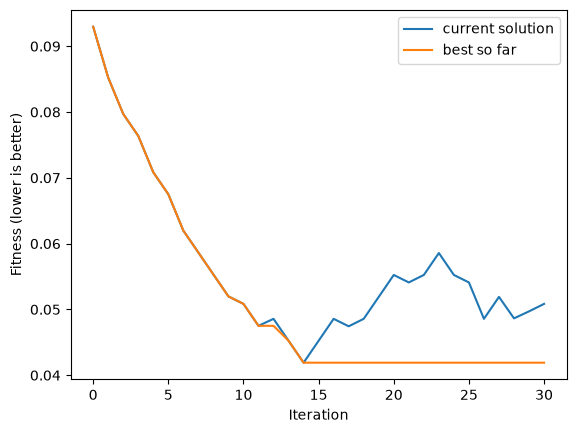

In [32]:
# Reproducible initial solution
rng = np.random.default_rng(42)
s0 = rng.integers(0, 2, size=X_train.shape[1])
best_s, best_f, hist, best_hist, feature_count_history, move_history = tabu_search(fitness, s0, tenure=5, max_iter=30)

print("Best fitness:", round(best_f, 4), "| selected features:", int(best_s.sum()))
print([feature_names[i] for i in np.where(best_s == 1)[0]])

plt.plot(hist, label="current solution")
plt.plot(best_hist, label="best so far")
plt.xlabel("Iteration")
plt.ylabel("Fitness (lower is better)")
plt.legend()
plt.show()


tabu algo stats


In [33]:
# Fit the selected-feature model and compare it with using every feature.
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
    cohen_kappa_score, confusion_matrix, classification_report, log_loss)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

selected_idx = np.flatnonzero(best_s)
if len(selected_idx) == 0:
    raise ValueError("Tabu search selected no features; increase the search budget or change initialization.")

selected_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
full_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
selected_model.fit(X_train[:, selected_idx], y_train)
full_model.fit(X_train, y_train)

# Repeated evaluation on the untouched holdout set (one estimate per model).
def collect_metrics(model, X_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_test, pred),
        "balanced accuracy": balanced_accuracy_score(y_test, pred),
        "precision (malignant)": precision_score(y_test, pred, zero_division=0),
        "recall / sensitivity": recall_score(y_test, pred, zero_division=0),
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, prob),
        "PR AUC (average precision)": average_precision_score(y_test, prob),
        "MCC": matthews_corrcoef(y_test, pred),
        "Cohen kappa": cohen_kappa_score(y_test, pred),
        "log loss": log_loss(y_test, prob, labels=[0, 1]),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

stats = pd.DataFrame({
    "Tabu selected": collect_metrics(selected_model, X_test[:, selected_idx]),
    "All features": collect_metrics(full_model, X_test),
}).T
stats.insert(0, "feature count", [len(selected_idx), X_train.shape[1]])
print("Holdout metrics (positive class = malignant):")
display(stats.round(4))
print("\nSelected features:", ", ".join(feature_names[i] for i in selected_idx))
print("\nClassification report — selected model:")
print(classification_report(y_test, selected_model.predict(X_test[:, selected_idx]),
                            target_names=["benign", "malignant"], zero_division=0))
print("Confusion matrix (rows=true, columns=predicted; benign, malignant):")
print(confusion_matrix(y_test, selected_model.predict(X_test[:, selected_idx]), labels=[0, 1]))

# Separate the two pieces of the search objective for interpretation.
cv_error = error_rate(best_s)
complexity_penalty = 0.1 * len(selected_idx) / X_train.shape[1]
print(f"\nTabu objective: {best_f:.4f} = CV error {cv_error:.4f} + feature penalty {complexity_penalty:.4f}")
print(f"Selected {len(selected_idx)}/{X_train.shape[1]} features ({100*len(selected_idx)/X_train.shape[1]:.1f}%).")


Holdout metrics (positive class = malignant):


,feature count,accuracy,balanced accuracy,precision (malignant),recall / sensitivity,specificity,F1,ROC AUC,PR AUC (average precision),MCC,Cohen kappa,log loss,TN,FP,FN,TP
Tabu selected,4,0.9474,0.9385,0.950,0.9048,0.9722,0.9268,0.9901,0.9846,0.8864,0.8858,0.1320,70.0,2.0,4.0,38.0
All features,30,0.9649,0.9573,0.975,0.9286,0.9861,0.9512,0.9960,0.9943,0.9245,0.9238,0.0773,71.0,1.0,3.0,39.0



Selected features: texture_mean, perimeter_mean, smoothness_worst, symmetry_worst

Classification report — selected model:
              precision    recall  f1-score   support

      benign       0.95      0.97      0.96        72
   malignant       0.95      0.90      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

Confusion matrix (rows=true, columns=predicted; benign, malignant):
[[70  2]
 [ 4 38]]

Tabu objective: 0.0419 = CV error 0.0286 + feature penalty 0.0133
Selected 4/30 features (13.3%).


In [34]:
spam = fetch_ucirepo(id=94)
X_spam = spam.data.features
y_spam = spam.data.targets.squeeze()

df_spam = pd.concat([X_spam, y_spam.rename("target")], axis=1)


In [35]:
df_spam

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,target
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88,0
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14,0
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118,0
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78,0


### Additional diagnostics
The out-of-fold metrics below are descriptive: because the subset was already chosen using cross-validation, they can be optimistic. The final holdout metrics are the cleaner estimate. Bootstrap intervals summarize uncertainty for the fixed holdout predictions and do not include feature-search variability.


In [36]:
# Stratified 5-fold out-of-fold estimates on training data for the selected subset.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_estimator = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
oof_prob = cross_val_predict(cv_estimator, X_train[:, selected_idx], y_train,
                             cv=cv, method="predict_proba")[:, 1]
oof_pred = (oof_prob >= 0.5).astype(int)
print("Training 5-fold out-of-fold metrics:")
print(pd.Series({
    "accuracy": accuracy_score(y_train, oof_pred),
    "balanced accuracy": balanced_accuracy_score(y_train, oof_pred),
    "precision": precision_score(y_train, oof_pred, zero_division=0),
    "recall / sensitivity": recall_score(y_train, oof_pred, zero_division=0),
    "F1": f1_score(y_train, oof_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_train, oof_prob),
    "PR AUC": average_precision_score(y_train, oof_prob),
}).round(4))

# Bootstrap percentile intervals on the fixed test predictions.
# These intervals quantify sampling uncertainty; they do not include search variability.
def bootstrap_metric_ci(y_true, y_pred, y_prob, metric, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        ix = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[ix])) < 2:
            continue
        vals.append(metric(y_true[ix], y_pred[ix], y_prob[ix]))
    return np.quantile(vals, [0.025, 0.975])

y_pred_test = selected_model.predict(X_test[:, selected_idx])
y_prob_test = selected_model.predict_proba(X_test[:, selected_idx])[:, 1]
metrics_for_ci = {
    "accuracy": lambda yt, yp, pr: accuracy_score(yt, yp),
    "balanced accuracy": lambda yt, yp, pr: balanced_accuracy_score(yt, yp),
    "F1": lambda yt, yp, pr: f1_score(yt, yp, zero_division=0),
    "ROC AUC": lambda yt, yp, pr: roc_auc_score(yt, pr),
    "PR AUC": lambda yt, yp, pr: average_precision_score(yt, pr),
}
ci_rows = []
for name, metric in metrics_for_ci.items():
    lo, hi = bootstrap_metric_ci(y_test, y_pred_test, y_prob_test, metric)
    ci_rows.append({"metric": name, "estimate": metric(y_test, y_pred_test, y_prob_test),
                    "95% bootstrap CI lower": lo, "95% bootstrap CI upper": hi})
display(pd.DataFrame(ci_rows).set_index("metric").round(4))

# Selected-feature coefficients from the fitted logistic regression (standardized inputs).
coef = selected_model[-1].coef_[0]
coef_table = pd.DataFrame({"feature": [feature_names[i] for i in selected_idx],
                           "coefficient": coef, "odds ratio per scaled unit": np.exp(coef)})
display(coef_table.reindex(coef_table.coefficient.abs().sort_values(ascending=False).index).round(4))


Training 5-fold out-of-fold metrics:
accuracy                0.9670
balanced accuracy       0.9606
precision               0.9755
recall / sensitivity    0.9353
F1                      0.9550
ROC AUC                 0.9876
PR AUC                  0.9868
dtype: float64


,estimate,95% bootstrap CI lower,95% bootstrap CI upper
metric,,,
accuracy,0.9474,0.9035,0.9825
balanced accuracy,0.9385,0.8859,0.9815
F1,0.9268,0.8605,0.9773
ROC AUC,0.9901,0.9757,0.9987
PR AUC,0.9846,0.9621,0.9980


,feature,coefficient,odds ratio per scaled unit
1,perimeter_mean,4.0980,60.2221
2,smoothness_worst,1.3433,3.8317
0,texture_mean,1.1846,3.2693
3,symmetry_worst,1.0225,2.7801


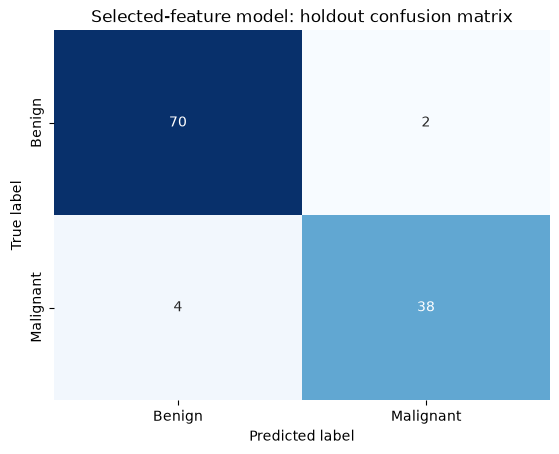

In [37]:
# Confusion matrix heatmap for the selected model.
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Selected-feature model: holdout confusion matrix")
plt.show()


### Tabu search result plots
These plots summarize the search trajectory and compare the final selected-feature model with an all-feature logistic-regression baseline. The saved `stats` table and these evaluation definitions can be reused for other feature-selection algorithms on the same fixed split.

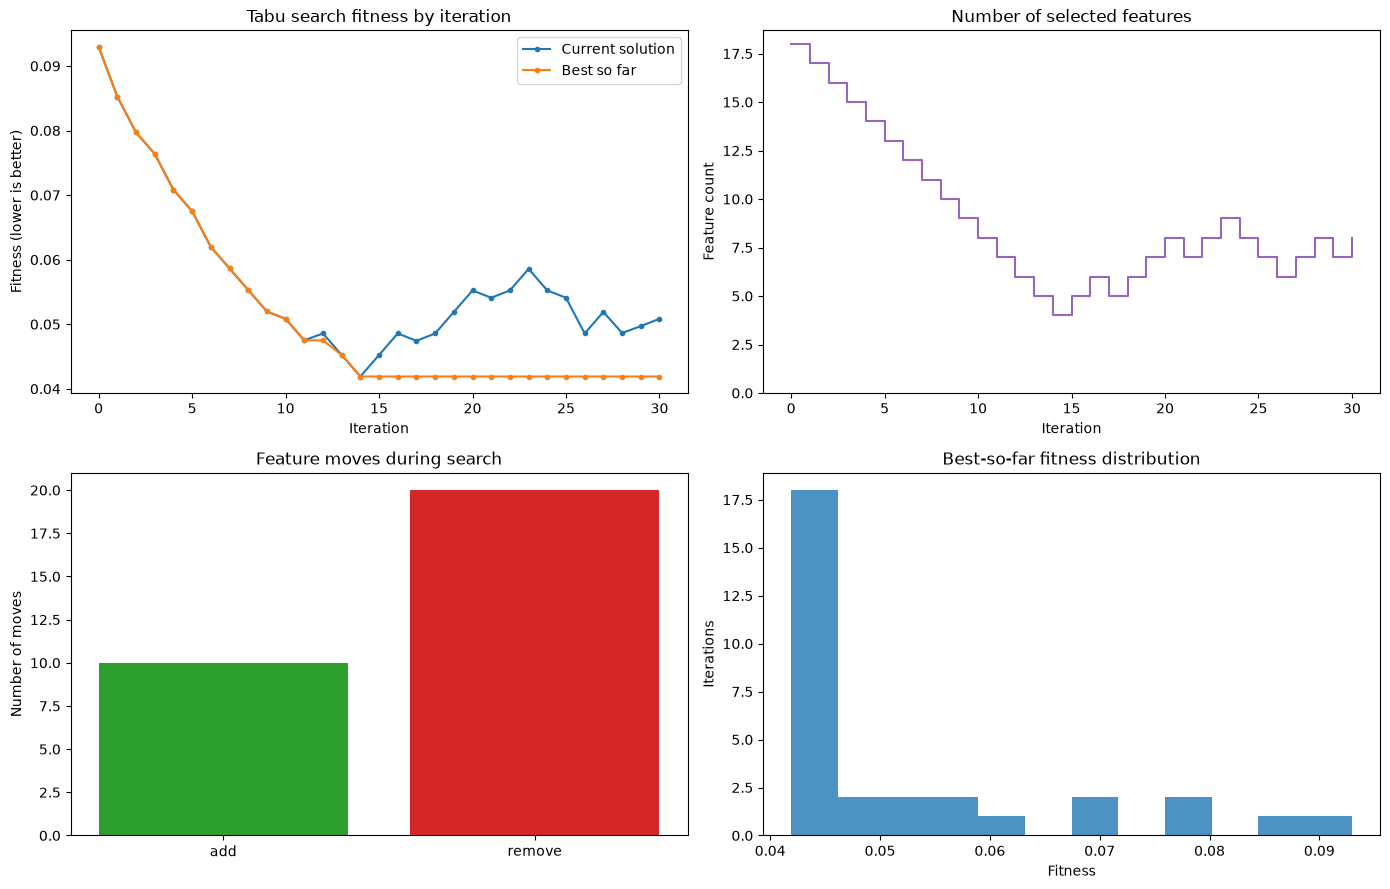

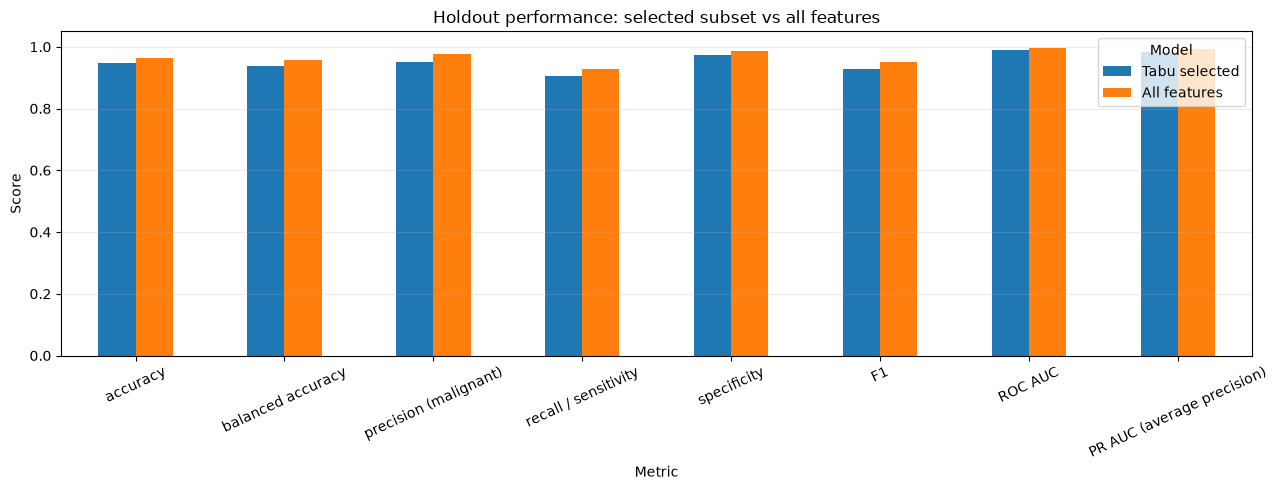

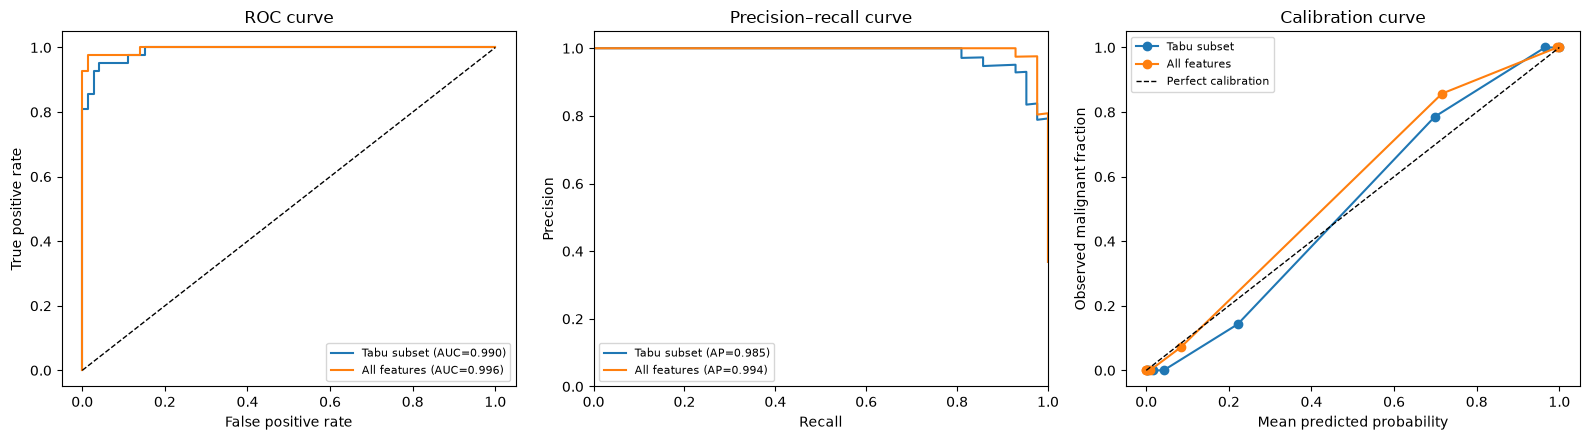

In [38]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

iterations = np.arange(len(hist))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(iterations, hist, marker="o", ms=3, label="Current solution")
axes[0, 0].plot(iterations, best_hist, marker=".", label="Best so far")
axes[0, 0].set(title="Tabu search fitness by iteration", xlabel="Iteration", ylabel="Fitness (lower is better)")
axes[0, 0].legend()
axes[0, 1].step(np.arange(len(feature_count_history)), feature_count_history, where="post", color="tab:purple")
axes[0, 1].set(title="Number of selected features", xlabel="Iteration", ylabel="Feature count")
axes[0, 1].set_ylim(bottom=0)

if move_history:
    moved = pd.Series([action for _, action in move_history]).value_counts().reindex(["add", "remove"], fill_value=0)
    axes[1, 0].bar(moved.index, moved.values, color=["tab:green", "tab:red"])
    axes[1, 0].set(title="Feature moves during search", ylabel="Number of moves")
else:
    axes[1, 0].text(0.5, 0.5, "No moves made", ha="center", va="center")
    axes[1, 0].set_axis_off()
axes[1, 1].hist(best_hist, bins=min(12, max(3, len(best_hist))), color="tab:blue", alpha=0.8)
axes[1, 1].set(title="Best-so-far fitness distribution", xlabel="Fitness", ylabel="Iterations")
fig.tight_layout()
plt.show()

# Metric comparison on the same held-out cases. Useful as a standard plot for other algorithms.
metric_names = ["accuracy", "balanced accuracy", "precision (malignant)",
                "recall / sensitivity", "specificity", "F1", "ROC AUC",
                "PR AUC (average precision)"]
metric_plot = stats.loc[:, metric_names].T
ax = metric_plot.plot(kind="bar", figsize=(13, 5), ylim=(0, 1.05), rot=25)
ax.set(title="Holdout performance: selected subset vs all features", ylabel="Score", xlabel="Metric")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Threshold-independent ranking curves and probability calibration.
y_test_pred = selected_model.predict(X_test[:, selected_idx])
y_test_prob = selected_model.predict_proba(X_test[:, selected_idx])[:, 1]
y_full_prob = full_model.predict_proba(X_test)[:, 1]
fpr_sel, tpr_sel, _ = roc_curve(y_test, y_test_prob)
fpr_full, tpr_full, _ = roc_curve(y_test, y_full_prob)
prec_sel, rec_sel, _ = precision_recall_curve(y_test, y_test_prob)
prec_full, rec_full, _ = precision_recall_curve(y_test, y_full_prob)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(fpr_sel, tpr_sel, label=f"Tabu subset (AUC={roc_auc_score(y_test, y_test_prob):.3f})")
axes[0].plot(fpr_full, tpr_full, label=f"All features (AUC={roc_auc_score(y_test, y_full_prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(fontsize=8)
axes[1].plot(rec_sel, prec_sel, label=f"Tabu subset (AP={average_precision_score(y_test, y_test_prob):.3f})")
axes[1].plot(rec_full, prec_full, label=f"All features (AP={average_precision_score(y_test, y_full_prob):.3f})")
axes[1].set(title="Precision–recall curve", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.05))
axes[1].legend(fontsize=8)
for prob, label in [(y_test_prob, "Tabu subset"), (y_full_prob, "All features")]:
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=8, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, marker="o", label=label)
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
axes[2].set(title="Calibration curve", xlabel="Mean predicted probability", ylabel="Observed malignant fraction")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()
